Training a RNN off the scraped quotes. There's only 100 quotes, so a rather small set to work with

I'm pretty new to machine learning at the time of writing, a lot of the framework for the RNN comes from the CrashCourse AI Lab #7 on Natural Language Processing, with a certain amount of modifications(i.e. swapping out now deprecated functions, removing code that isnt needed, and turning knobs and dials on the model such as training time, batch size, seq length, temperature etc.)



In [1]:
#clean up the dataset initially by removing quotes and other punctuation, then subset the string to just the quotes and export
import pandas as pd
import string

df = pd.read_csv('scrapedquotes.csv')

df['Quote'] = df['Quote'].astype(str).str.replace(r'[#""“”]', '', regex=True) # regex removal of quotation marks
def remove_punctuations(text):
    if not isinstance(text, str):
        return text
    return text.translate(str.maketrans('', '', string.punctuation))


df['Quote'] = df['Quote'].apply(remove_punctuations)
df = df['Quote']
df.head()

0    The world as we have created it is a process o...
1    It is our choices Harry that show what we trul...
2    There are only two ways to live your life One ...
3    The person be it gentleman or lady who has not...
4    Imperfection is beauty madness is genius and i...
Name: Quote, dtype: str

In [2]:
df.to_csv('trainingdata.txt', sep='\n', index=False) 

In [3]:
with open('trainingdata.txt', "r", encoding="ascii",errors="ignore") as file:
    txt = [line.strip() for line in file.readlines()]
everything = set([w for s in txt for w in s.split()])
print(f"Dataset contains {len(txt)} quotes and {len(everything)} lexical types")

Dataset contains 101 quotes and 726 lexical types


In [4]:
#tokenization
import spacy
nlp = spacy.load("en_core_web_sm", disable=["parser","tagger","ner","textcat","lemmatizer"])

# 2. Tokenize
txt = [nlp(s) for s in txt]

# 3. Mark the beginning and end of each script
txt = [ ["<s>"] + [str(w) for w in s] + ["</s>"] for s in txt]

# 4. Separate the data into training and validation
train = txt[:-5]
valid = txt[-5:]

# 5. Flatten the lists into one long string and remove extra whitespace
train = [w for s in train for w in s if not w.isspace()]
valid = [w for s in valid for w in s if not w.isspace()]

In [5]:

print("Our training dataset contains {} lexical types".format(len(set(train))))
print("Our training dataset contains {} lexical tokens".format(len(train)))

Our training dataset contains 698 lexical types
Our training dataset contains 2503 lexical tokens


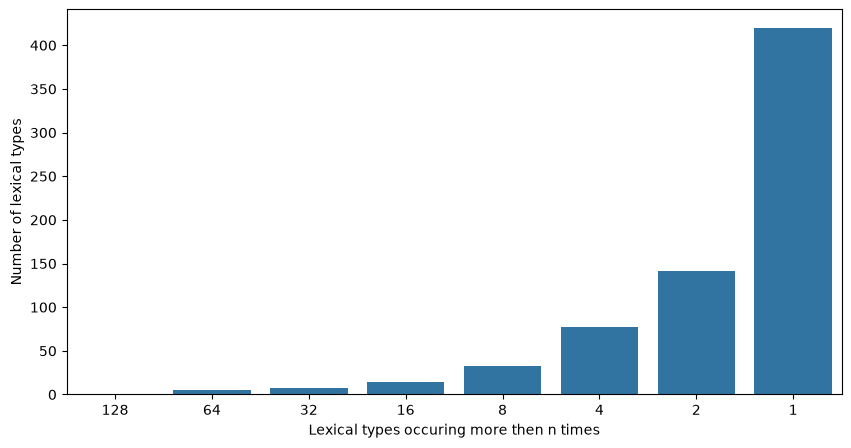

In [6]:

# Count the frequencies of every word
from collections import Counter, defaultdict
counts = Counter(train)

frequencies = [0]*8
for w in counts:
  if counts[w] >= 128:
    frequencies[0] += 1
  elif counts[w] >= 64:
    frequencies[1] += 1
  elif counts[w] >= 32:
    frequencies[2] += 1
  elif counts[w] >= 16:
    frequencies[3] += 1
  elif counts[w] >= 8:
    frequencies[4] += 1
  elif counts[w] >= 4:
    frequencies[5] += 1
  elif counts[w] >= 2:
    frequencies[6] += 1
  else:
    frequencies[7] += 1


# 2. Plot their distributions
import matplotlib.pyplot as plt
import seaborn as sns

f,a = plt.subplots(1,1,figsize=(10,5))
a.set(xlabel='Lexical types occuring more then n times',
      ylabel='Number of lexical types')

labels = [128, 64, 32, 16, 8, 4, 2, 1]
_ = sns.barplot(x=labels, y=frequencies, ax=a, order=labels)

In [7]:
# see rare workds that occur once
from textwrap import wrap
rare = [w for w in counts if counts[w] == 1]
for line in wrap("   ".join(["{:15s}".format(w) for w in rare[:100]]), width=70):
  print(line)

Quote             created           process           changed
changing          choices           show              far
abilities         gentleman         lady              pleasure
novel             intolerably       Imperfection      beauty
madness           ridiculous        boring            Try
success           Rather            value             hated
failed            found             10000             wo
work              bag               strong            until
hot               water             sunshine          night
This              No                matter            sometimes
universal         decide            Girls             act
anyway            stay              Also              sisters
As                lovers            baby              actually
pretty            break             soulmate          whole
goes              Just              once              gon
na                Keep              sweetie           chin
importantly       lifes             s

In [8]:
import re
def simplify(w):

    # Replace numbers with # sign
    w = re.sub('\\d', '#', w)

    # Change some endings
    if len(w) > 3 and w[-2:] in set(["ed", "er","ly"]):
        return [w[:-2], w[-2:]]
    elif len(w) > 4 and w[-3:] in set(["ing","'re"]):
        return [w[:-3], w[-3:]]
    return [w]

671 lexical types
2682 lexical tokens


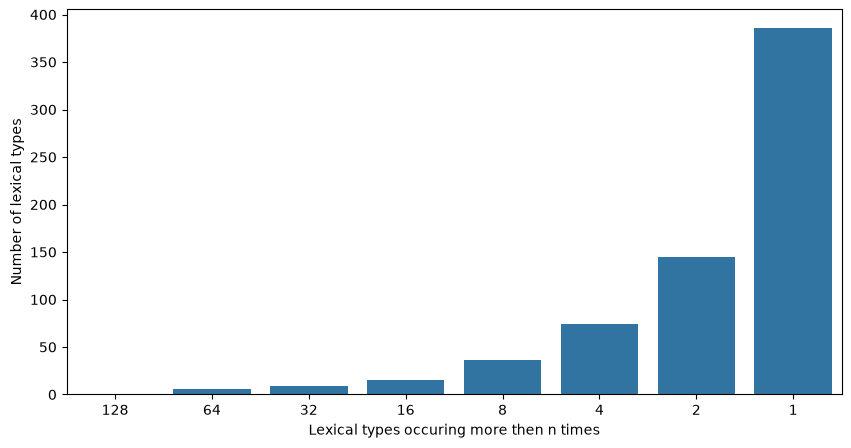

In [9]:
# 1. Go through and clean all of our data
train_clean = []
for w in train:
    for piece in simplify(w):
        train_clean.append(piece)
valid_clean = []
for w in valid:
    for piece in simplify(w):
        valid_clean.append(piece)

"""
    How big is our dataset?
"""
print("{} lexical types".format(len(set(train_clean))))
print("{} lexical tokens".format(len(train_clean)))

"""
    What's our distribution look like?
"""
counts = Counter(train_clean)


frequencies = [0]*8
for w in counts:
  if counts[w] >= 128:
    frequencies[0] += 1
  elif counts[w] >= 64:
    frequencies[1] += 1
  elif counts[w] >= 32:
    frequencies[2] += 1
  elif counts[w] >= 16:
    frequencies[3] += 1
  elif counts[w] >= 8:
    frequencies[4] += 1
  elif counts[w] >= 4:
    frequencies[5] += 1
  elif counts[w] >= 2:
    frequencies[6] += 1
  else:
    frequencies[7] += 1


# 2. Plot their distributions
f,a = plt.subplots(1,1,figsize=(10,5))
a.set(xlabel='Lexical types occuring more then n times',
      ylabel='Number of lexical types')

labels = [128, 64, 32, 16, 8, 4, 2, 1]
_ = sns.barplot(x=labels, y=frequencies, ax=a, order=labels)

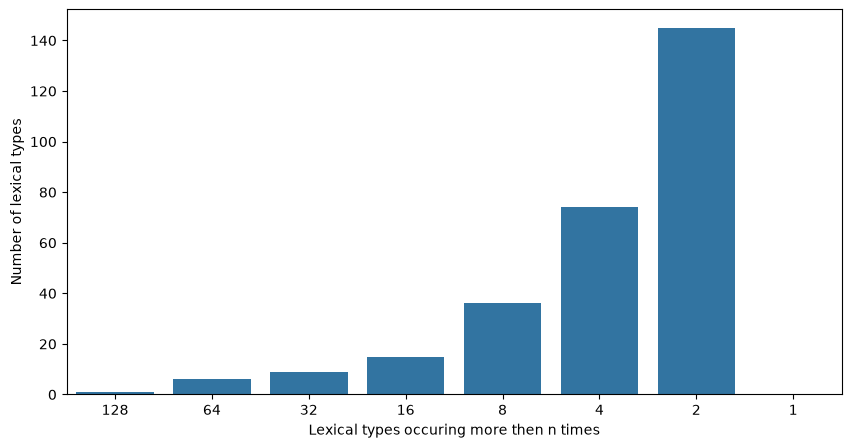

In [10]:
counts_clean = Counter(train_clean)
train_unk = [w if counts_clean[w] > 1 else "unk" for w in train_clean]
valid_unk = [w if w in counts_clean and counts_clean[w] > 1 \
               else "unk" for w in valid_clean]

# Let's plot these one last time
counts = Counter(train_unk)

frequencies = [0]*8
for w in counts:
  if counts[w] >= 128:
    frequencies[0] += 1
  elif counts[w] >= 64:
    frequencies[1] += 1
  elif counts[w] >= 32:
    frequencies[2] += 1
  elif counts[w] >= 16:
    frequencies[3] += 1
  elif counts[w] >= 8:
    frequencies[4] += 1
  elif counts[w] >= 4:
    frequencies[5] += 1
  elif counts[w] >= 2:
    frequencies[6] += 1
  else:
    frequencies[7] += 1


# 2. Plot their distributions
f,a = plt.subplots(1,1,figsize=(10,5))
a.set(xlabel='Lexical types occuring more then n times',
      ylabel='Number of lexical types')

labels = [128, 64, 32, 16, 8, 4, 2, 1]
_ = sns.barplot(x=labels, y=frequencies, ax=a, order=labels)

In [11]:
rare = [w for w in counts_clean if counts_clean[w] == 1]
rare.sort()
for line in wrap("   ".join(["{:15s}".format(w) for w in rare[-100:]]), width=70):
  print(line)

put               putt              question          rapid
reads             ready             reason            rid
ridiculous        risen             round             said
scares            school            second            seconds
seem              selfishness       sense             serene
shoes             show              sigh              simp
sin               sisters           sit               six
sixty             sleepy            smile             someday
sometimes         soulmate          space             spirit
star              stars             start             stay
still             stop              stray             strong
stupidity         success           suffer            suit
sun               sunshine          sure              sweetie
talk              terms             terrible          terrific
therefore         thousand          thrill            tires
togeth            travel            treat             tri
trouble           trust             tu

In [12]:
# STEP 2.1

"""
  Prepare our datasets by converting words to numbers
"""
# Create a mapping from words <-> numbers
vocabulary = set(train_unk)
word_to_num = {}
num_to_word = {}
for num, word in enumerate(vocabulary):
  word_to_num[word] = num
  num_to_word[num] = word

# Convert our datasets into numbers
import torch
train = torch.LongTensor(len(train_unk))
for i in range(len(train_unk)):
  train[i] = word_to_num[train_unk[i]]

valid = torch.LongTensor(len(valid_unk))
for i in range(len(valid_unk)):
  valid[i] = word_to_num[valid_unk[i]]

In [13]:

# Parameters
batch_size = 5
seq_len = 8

# Tell Torch to use a GPU for computation
device = torch.device("cuda")
# Setting the random seed decreases variability
# Remove next three lines if running on your laptop
torch.manual_seed(0)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# citation: https://github.com/pytorch/examples/tree/master/word_language_model
def batchify(data, bsz):
    # Work out how cleanly we can divide the dataset into bsz parts.
    nbatch = data.size(0) // bsz
    # Trim off any extra elements that wouldn't cleanly fit (remainders).
    data = data.narrow(0, 0, nbatch * bsz)
    # Evenly divide the data across the bsz batches.
    data = data.view(bsz, -1).t().contiguous()
    return data.to(device)

def get_batch(source, i, seq_len):
    seq_len = min(seq_len, len(source) - 1 - i)
    data = source[i:i+seq_len]
    target = source[i+1:i+1+seq_len].view(-1)
    return data, target

def repackage_hidden(h):
    """Wraps hidden states in new Tensors, to detach them from their history."""
    if isinstance(h, torch.Tensor):
        return h.detach()
    else:
        return tuple(repackage_hidden(v) for v in h)

train = batchify(train, batch_size)
valid = batchify(valid, batch_size)

In [14]:

import torch.nn as nn

class EncoderDecoder(nn.Module):
  def __init__(self):
    """
        Define all the parameters of the model
    """
    super(EncoderDecoder, self).__init__()
    # How tightly should we compress our language represenations?
    self.embed_size = 64     # How big is our word vector   #ADVANCED_CHANGEME
    self.hidden_size = 128     # How big is our hidden space  #ADVANCED_CHANGEME

    """ Converting words to Vectors """
    # A lookup table for translating a word into a vector
    self.embedding = nn.Embedding(len(vocabulary), self.embed_size)
    # Initialize our word vectors with a random uniform distribution
    initrange = 0.1
    self.embedding.weight.data.uniform_(-initrange, initrange)


    """ An RNN (LSTM) with dropout """
    self.rnn = nn.LSTM(input_size=self.embed_size, hidden_size=self.hidden_size)
    self.shrink = nn.Linear(self.hidden_size, self.embed_size)
    self.drop = nn.Dropout(p=0.5)

    """ Predicting words from our model """
    # We convert our vector to a set of scores over words
    self.decode = nn.Linear(self.embed_size, self.embedding.weight.size(0))
    # We use the same matrix for this ``decoding'' that we used for ``encoding''
    # https://arxiv.org/abs/1608.05859
    self.decode.weight = self.embedding.weight
    self.decode.bias.data.zero_()


  def forward(self, input, hidden=None):
    """
        Run the model
    """
    # 1. Map words to vectors
    embedded = self.embedding(input)
    # 2. Process with an RNN
    if hidden is not None:
      output, hidden = self.rnn(embedded, hidden)
    else:
      output, hidden = self.rnn(embedded)
    # 3. Apply dropout
    output = F.relu(self.shrink(self.drop(output)))
    # 4. Score the likelihood of every possible next word
    decoded = self.decode(output)
    return hidden, decoded

In [15]:
import torch.nn.functional as F
def training(model, data, targets, lr, hidden):
  # Reset the model
  model.zero_grad()

  # Run the model to see its predictions and hidden states
  hidden, prediction_vector = model(data, hidden)
  prediction_vector = prediction_vector.view(-1, len(vocabulary))

  # Compare the model's predictions at each timestep to the original data
  loss = F.cross_entropy(prediction_vector, targets)

  # Compute gradients and perform back-propagation
  loss.backward()
  torch.nn.utils.clip_grad_norm_(model.parameters(), 0.25)
  for p in model.parameters():
      if p.grad is not None:
        p.data.add_(-lr, p.grad.data)

  # Return the current model loss on this data item
  return loss.item(), repackage_hidden(hidden)

In [16]:
# STEP 3.2

def evaluation(model):
  """
    This function performs almost all the same logic as the training function
    but it does not perform backpropagation, because we don't want to learn
    from this data, just check our performance.
  """
  model.eval()
  hidden = None
  valid_loss = 0
  for i in range(0, valid.size(0) - seq_len, seq_len):
    data, targets = get_batch(valid, i, seq_len)
    hidden, prediction_vector = model(data, hidden)
    hidden = repackage_hidden(hidden)

    prediction_vector = prediction_vector.view(-1, len(vocabulary))
    loss = F.cross_entropy(prediction_vector, targets)
    valid_loss += loss.item()
  return valid_loss / (valid.size(0)/seq_len)

In [17]:
# STEP 3.3

# Create an instance of the model
import numpy as np
import time
model = EncoderDecoder().float().to(device)
prev_valid_loss = 1e100
# This scales the size of each step of backpropagation
learning_rate = 20
# This value should match the batch_size used earlier for splitting up the data
batch_size = 5

num_epochs = 25
timing = time.time()
for epoch in range(num_epochs):

  # Set the model to training mode and iterate through the dataset
  model.train()
  hidden = None
  train_loss = 0
  start_time = time.time()
  for i in range(0, train.size(0) - 1, seq_len):
    # Get the next training batch
    data, targets = get_batch(train, i, seq_len)

    # Run the model and perform backpropagation
    loss, hidden = training(model, data, targets, learning_rate, hidden)
    train_loss += loss

  # Evaluate how well the model predicts unseen validation data
  valid_loss = evaluation(model)

  # Check if the model's ability to generalize has gotten worse.
  # If so, slow the learning rate (shrink the step size)
  if valid_loss > prev_valid_loss:
    learning_rate /= 4.0

  # Print the training and validation performance
  train_loss /= (train.size(0)/seq_len)
  finish_time = time.time()
  print("Epoch {:2} took {:3.2f}s with train perplexity: {:7.2f}"\
        " and validation: {:7.2f}".format(epoch, finish_time - start_time,
                                          np.exp(train_loss),
                                          np.exp(valid_loss)))

  prev_valid_loss = valid_loss

total_time = (time.time() - timing)/60
print("Completed {} epochs in {:5.3f} minutes".format(num_epochs, total_time))

/tmp/ipykernel_37065/2094222489.py:18: UserWarning: This overload of add_ is deprecated:
	add_(Number alpha, Tensor other)
Consider using one of the following signatures instead:
	add_(Tensor other, *, Number alpha = 1) (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/python_arg_parser.cpp:1841.)
  p.data.add_(-lr, p.grad.data)


Epoch  0 took 0.38s with train perplexity:  152.82 and validation:   22.05
Epoch  1 took 0.21s with train perplexity:  135.46 and validation:   22.06
Epoch  2 took 0.22s with train perplexity:  109.60 and validation:   23.01
Epoch  3 took 0.23s with train perplexity:  105.44 and validation:   23.28
Epoch  4 took 0.31s with train perplexity:  104.05 and validation:   23.05
Epoch  5 took 0.29s with train perplexity:  103.89 and validation:   23.05
Epoch  6 took 0.22s with train perplexity:  103.80 and validation:   23.06
Epoch  7 took 0.28s with train perplexity:  103.51 and validation:   23.02
Epoch  8 took 0.28s with train perplexity:  103.48 and validation:   23.00
Epoch  9 took 0.25s with train perplexity:  103.47 and validation:   22.99
Epoch 10 took 0.29s with train perplexity:  103.45 and validation:   22.99
Epoch 11 took 0.32s with train perplexity:  103.44 and validation:   22.99
Epoch 12 took 0.27s with train perplexity:  103.43 and validation:   22.99
Epoch 13 took 0.13s with 

In [50]:
# What do we want the model to start the sentence with?
prefix = "love"  

# How many words do we want the model to produce?
words_to_generate = 20

# We are only going to be looking at one example at a time
batch_size = 1

# Set the model to be in evaluation mode (no backprop!)
model.eval()

# Let's get lots of possible sentences
argmax_sent = None
argmax_prob = 0
collection = []
for item in range(100):
  # Convert our sentence start into numbers
  test = [word_to_num[word] if word in word_to_num else word_to_num["unk"] \
          for word in prefix.split()]
  probabilities = []

  # Run the model on the same initial input and it's own generations until hitting words_to_generate
  for w in range(words_to_generate):
    # Run the model
    input = torch.from_numpy(np.array(test)).to(device)
    _, output = model(input.view(-1,1))

    # Get the prediction for the last (next) word
    last_pred = output[-1,:,:].squeeze()

    # block generation of unneeded characters
    last_pred[word_to_num["unk"]] = -1000
    last_pred[word_to_num["</s>"]] = -1000
    last_pred[word_to_num["<s>"]] = -1000

    #repeat penalties
    for suffix in ["ing", "er", "ly", "ed", "nt"]:
        if suffix in word_to_num:
            last_pred[word_to_num[suffix]] = -1000

    if len(test) > 0:
        last_word_idx = test[-10:]
        last_pred[last_word_idx] -= 1000

    # Do we want to sample from this distrubtion?
    if item > 0:
      # A temperature makes the distribution peakier (if < 1) or flatter if > 1
      last_pred /= 1.5 #ADVANCED_CHANGEME

      # Turn this into a distribution
      dist = torch.distributions.categorical.Categorical(logits=last_pred)

      # Sample
      predicted_idx = dist.sample().item()

    else:
      # If we aren't sampling, just take the most probable word
      _, predicted_idx = last_pred.max(0)
      predicted_idx = predicted_idx.item()

    # Save the predicted word's probability
    value = F.log_softmax(last_pred,-1)[predicted_idx].item()

    # Add this predicted word (index) to the list
    test.append(predicted_idx)
    # Save the probability for sorting later
    probabilities.append(value)

  if item > 0:
    # Add our sentence and its score to a list
    generation = (np.exp(np.sum(probabilities)), \
                       " ".join([num_to_word[w] for w in test]))
    if generation not in collection:
      collection.append(generation)
  else:
    argmax_sent = " ".join([num_to_word[w] for w in test])
    argmax_prob = np.exp(np.sum(probabilities))

# Get the best model predictions
collection.sort()
collection.reverse()
print("Argmax Generation:")
print("{:.2E}:  {}\n".format(argmax_prob,"\n\t\t".join(wrap(argmax_sent))))
print("\nSampled Generations:")
for probability, sent in collection[:10]:
  print("{:.2E}:  {}\n".format(probability, "\n\t\t".join(wrap(sent))))

Argmax Generation:
5.26E-30:  love you is to I a the and of it not be you is to I a the and of it


Sampled Generations:
7.44E-43:  love think door its I how on in you the and is go up casket I music be
		love in big

1.19E-43:  love not of but world I that One tales time and You it make go ll or
		between with a to

7.32E-44:  love between to I those more that people you my is part of There to
		them got it die with day

3.08E-44:  love think than I can no You it without If truth much feel you if is
		to because true So and

1.51E-44:  love is takes beautiful else I we in all book s ways not but your of
		then on The will you

4.72E-45:  love If is that must you a more way That the my matters I what think
		done where are mind head

4.04E-45:  love drink anyth that a out you tales want hate the just of but I
		often have everyth we to when

3.32E-45:  love are on there is happen of everyth people but up necessary in
		would heart you to not high what takes

3.31E-45:  love is troubles